In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scienceplots as sp
plt.style.use('science')
from scipy.stats import gaussian_kde, spearmanr, pearsonr
plt.rcParams.update({'font.size': 28})
import matplotlib.ticker as ticker
from sklearn.metrics import r2_score, mean_absolute_percentage_error

## FINAL UNET RESULTS

In [2]:
with open('../Results/norm_stats.pkl', 'rb') as f:
    norm_stats = pickle.load(f)

norm_stats

{'min_fcmip': 15634616.0,
 'max_fcmip': 21247800.0,
 'min_fcmpr': 0.0,
 'max_fcmpr': 21179.091796875,
 'min_fcmir': 0.0,
 'max_fcmir': 25313.69921875,
 'min_pressure': np.float32(96.28905),
 'max_pressure': np.float32(104.03392)}

In [3]:
def inverse_min_max_norm(value, min_val, max_val):
    return value * (max_val - min_val) + min_val

0.06637429612731627
0.07566949668298664 9.784816031680522e-125
0.10881599472798359 1.0921959114252938e-181
3.4612438096971765
166.48608375854405


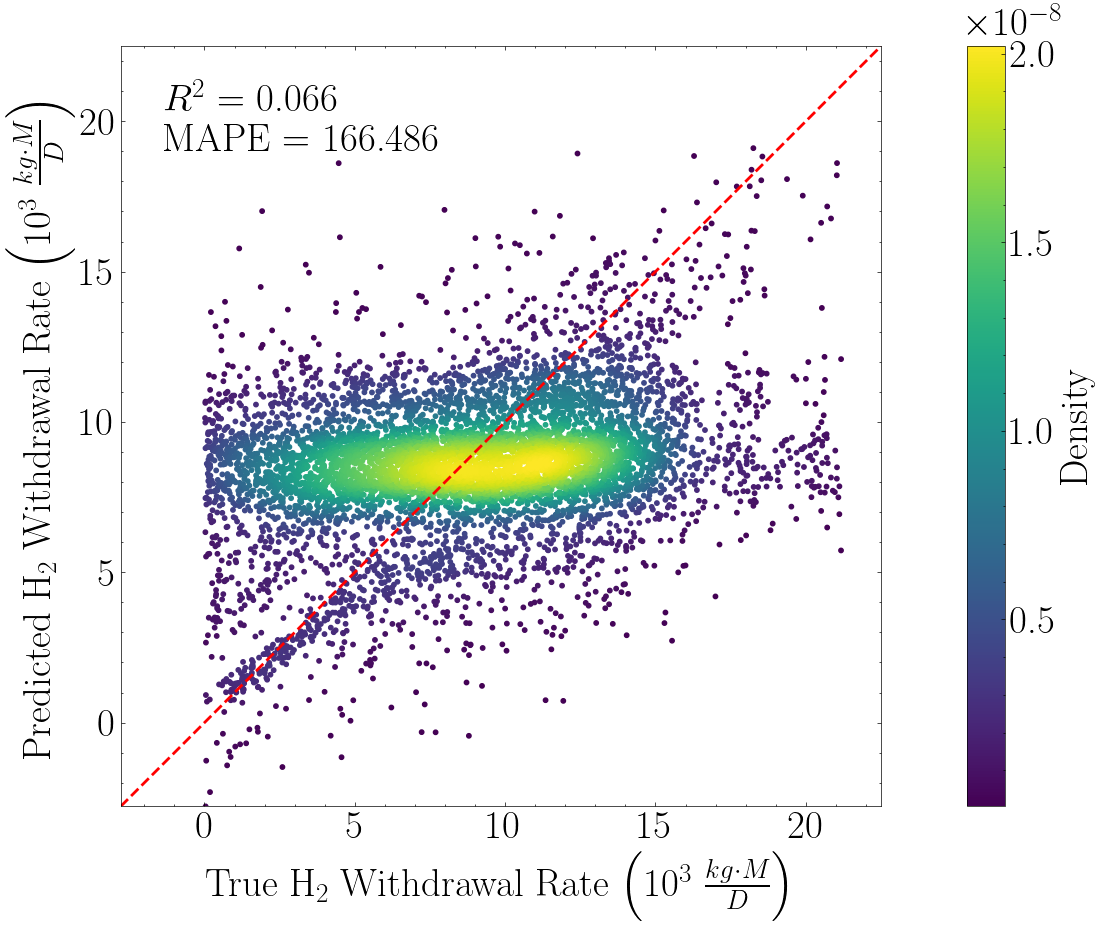

In [24]:
with open('../Results/Final_UNET_Prediction_dict.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

Dense_df = pd.DataFrame.from_dict(Dense_dict)

from sklearn.metrics import r2_score, mean_absolute_error

fig, ax = plt.subplots(figsize=(18, 10))

tw = Dense_df[Dense_df['True_test_with'] != 0]['True_test_with'].values
pw = Dense_df[Dense_df['True_test_with'] != 0]['Pred_test_with'].values

tw_arr = inverse_min_max_norm(np.array(tw), norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])
pw_arr = inverse_min_max_norm(np.array(pw), norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])

xy = np.vstack([tw_arr, pw_arr])
z = gaussian_kde(xy)(xy)

# Sort points by density so densest points plot on top
idx = z.argsort()
x, y, z = tw_arr[idx], pw_arr[idx], z[idx]

x = x/1000
y = y/1000

r2 = r2_score(x, y)
mae = mean_absolute_error(x, y)
rho, p_value = spearmanr(tw_arr, pw_arr)
r, p_value_pearson = pearsonr(tw_arr, pw_arr)
mape = mean_absolute_percentage_error(tw_arr, pw_arr) * 100

print(r2)
print(rho**2, p_value)
print(r**2, p_value_pearson)
print(mae)
print(mape)

lims = [min(x.min()-0.5, y.min()), 22.5]

sc = ax.scatter(x, y, alpha=1, cmap='viridis', c=z, s=10)

cbar = plt.colorbar(sc, label='Density')
# cbar.set_ticks([0, 2.0*10**-8, 4.0*10**-8, 6.0*10**-8, 8.0*10**-8])
# cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
ticks = np.array([ 0.5, 1, 1.5, 2]) * 1e-8   # whatever values suit your z range
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t/1e-8:.1f}' for t in ticks])
cbar.ax.set_title(r'$\times 10^{-8}$', fontsize=28, loc='left', pad=10)  # exponent label above colorbar
ax.plot(lims, lims, 'r--', label='y = x', linewidth=2)
ax.set_xlabel(r'True H$_2$ Withdrawal Rate $\left(10^3 \ \frac{kg \cdot M}{D} \right)$')
ax.set_ylabel(r'Predicted H$_2$ Withdrawal Rate $\left(10^3 \ \frac{kg \cdot M}{D} \right)$')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.text(0.0575, 0.95, f'$R^2$ = {r2:.3f} \n MAPE = {mape:.3f}', transform=ax.transAxes, fontsize=28, verticalalignment='top')
#ax.legend(loc='upper left')
ax.set_box_aspect(1)
plt.tight_layout()
fig.savefig('Figures/Withdrawal_scatter.png', dpi=300)
plt.show()

0.9783951886828406
0.9857479982148608 0.0
0.9785357806757973 0.0
0.43474505424941245
5.337650154692368


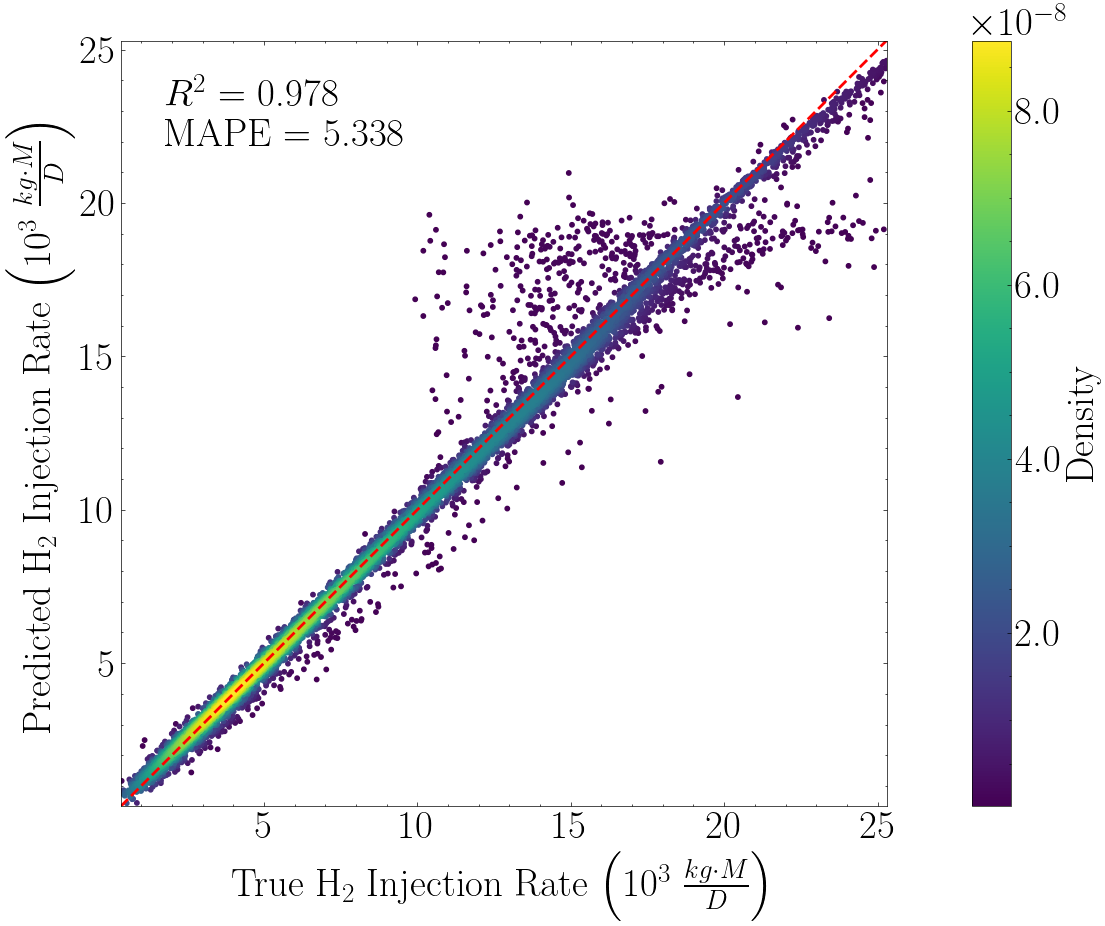

In [25]:
with open('../Results/Final_UNET_Prediction_dict.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)


Dense_df = pd.DataFrame.from_dict(Dense_dict)

from sklearn.metrics import r2_score

fig, ax = plt.subplots(figsize=(18, 10))

tw = Dense_df[Dense_df['True_test_inj'] != 0]['True_test_inj'].values
pw = Dense_df[Dense_df['True_test_inj'] != 0]['Pred_test_inj'].values

tw_arr = inverse_min_max_norm(np.array(tw), norm_stats['min_fcmir'], norm_stats['max_fcmir'])
pw_arr = inverse_min_max_norm(np.array(pw), norm_stats['min_fcmir'], norm_stats['max_fcmir'])

xy = np.vstack([tw_arr, pw_arr])
z = gaussian_kde(xy)(xy)

# Sort points by density so densest points plot on top
idx = z.argsort()
x, y, z = tw_arr[idx], pw_arr[idx], z[idx]

r2 = r2_score(tw_arr, pw_arr)
rho, p_value = spearmanr(tw_arr, pw_arr)
r, p_value_pearson = pearsonr(tw_arr, pw_arr)

x = x/1000
y = y/1000

mae = mean_absolute_error(x, y)
mae2 = np.abs(np.mean(x - y))
mape = mean_absolute_percentage_error(tw_arr, pw_arr) * 100

print(r2)
print(rho**2, p_value)
print(r**2, p_value_pearson)
print(mae)
print(mape)

lims = [min(x.min(), y.min()), max(x.max(), y.max())]

sc = ax.scatter(x, y, alpha=1, cmap='viridis', c=z, s=10)
cbar = plt.colorbar(sc, label='Density')
# cbar.set_ticks([0, 2.0*10**-8, 4.0*10**-8, 6.0*10**-8, 8.0*10**-8])
# cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
ticks = np.array([ 2, 4, 6, 8]) * 1e-8   # whatever values suit your z range
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t/1e-8:.1f}' for t in ticks])
cbar.ax.set_title(r'$\times 10^{-8}$', fontsize=28, loc='left')  # exponent label above colorbar
ax.set_xlabel(r'True H$_2$ Injection Rate $\left(10^3 \ \frac{kg \cdot M}{D} \right)$')
ax.set_ylabel(r'Predicted H$_2$ Injection Rate $\left(10^3 \ \frac{kg \cdot M}{D} \right)$')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.plot(lims, lims, 'r--', label='y = x', linewidth=2)
ax.text(0.0575, 0.95, f'$R^2$ = {r2:.3f} \n MAPE = {mape:.3f}', transform=ax.transAxes, fontsize=28, verticalalignment='top')
#ax.legend(loc='upper left')
ax.set_box_aspect(1)
plt.tight_layout()
fig.savefig('Figures/Injection_scatter.png', dpi=300)
plt.show()

0.9793627126689535
0.9698249559228694 0.0
0.9813011828302313 0.0
125466.27889098038
0.6492227040456033


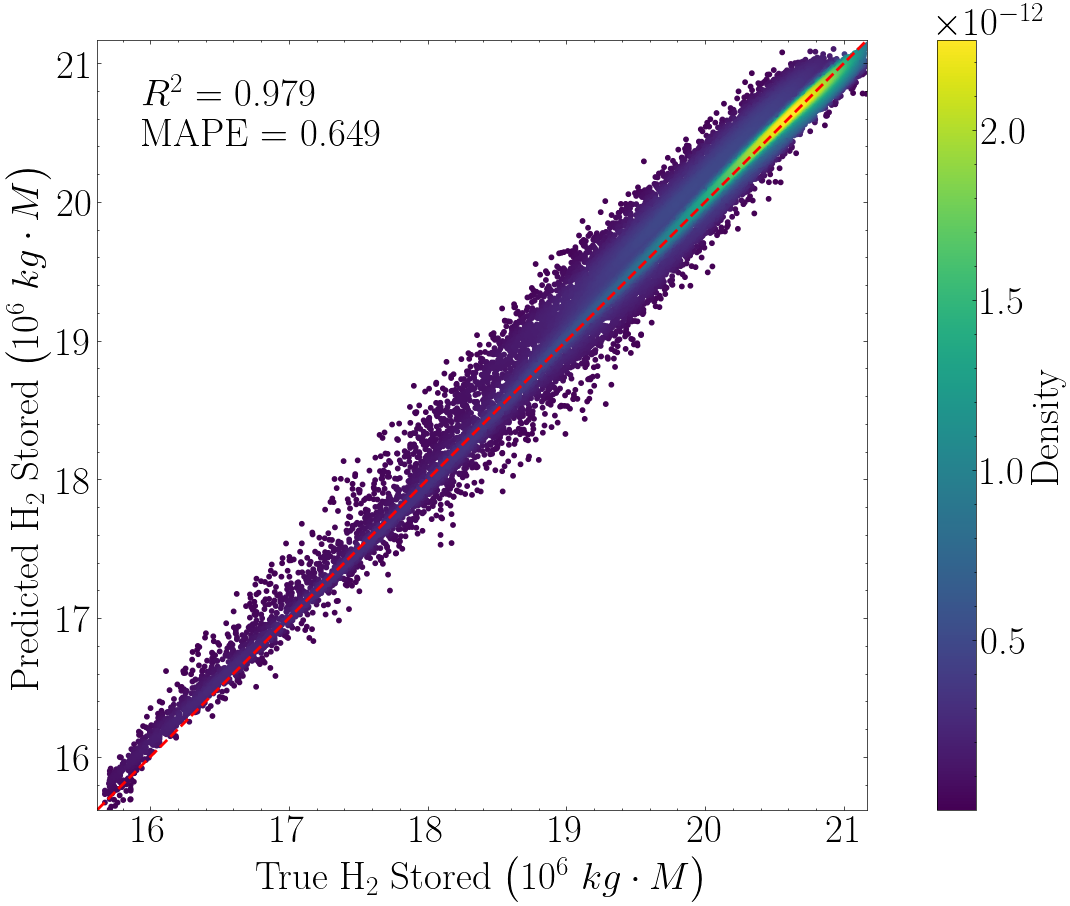

In [26]:
with open('../Results/Final_UNET_Prediction_dict.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

Dense_df = pd.DataFrame.from_dict(Dense_dict)

from sklearn.metrics import r2_score, mean_absolute_percentage_error

fig, ax = plt.subplots(figsize=(18, 10))

tw = Dense_df[Dense_df['True_test_inpl'] != 0]['True_test_inpl'].values
pw = Dense_df[Dense_df['True_test_inpl'] != 0]['Pred_test_inpl'].values

tw_arr = inverse_min_max_norm(np.array(tw), norm_stats['min_fcmip'], norm_stats['max_fcmip'])
pw_arr = inverse_min_max_norm(np.array(pw), norm_stats['min_fcmip'], norm_stats['max_fcmip'])

xy = np.vstack([tw_arr, pw_arr])
z = gaussian_kde(xy)(xy)


# Sort points by density so densest points plot on top
idx = z.argsort()
x, y, z = tw_arr[idx], pw_arr[idx], z[idx]

x = x/1000000
y = y/1000000


r2 = r2_score(tw_arr, pw_arr)
rho, p_value = spearmanr(tw_arr, pw_arr)
r, p_value_pearson = pearsonr(tw_arr, pw_arr)

mae = mean_absolute_error(tw_arr, pw_arr)
mape = mean_absolute_percentage_error(tw_arr, pw_arr) * 100

print(r2)
print(rho**2, p_value)
print(r**2, p_value_pearson)
print(mae)
print(mape)

lims = [min(x.min(), y.min()), max(x.max(), y.max())]

sc = ax.scatter(x, y, alpha=1, cmap='viridis', c=z, s=10)
cbar = plt.colorbar(sc, label='Density')
# cbar.set_ticks([0, 2.0*10**-8, 4.0*10**-8, 6.0*10**-8, 8.0*10**-8])
# cbar.ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
ticks = np.array([ 0.5, 1, 1.5, 2]) * 1e-12   # whatever values suit your z range
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{t/1e-12:.1f}' for t in ticks])
cbar.ax.set_title(r'$\times 10^{-12}$', fontsize=28, loc='left')  # exponent label above colorbar
ax.plot(lims, lims, 'r--', label='y = x', linewidth=2)
ax.set_xlabel(r'True H$_2$ Stored $\left( 10^6 \ {kg \cdot M} \right)$')
ax.set_ylabel(r'Predicted H$_2$ Stored $\left ( 10^6 \ {kg \cdot M} \right)$')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.text(0.0575, 0.95, f'$R^2$ = {r2:.3f} \n MAPE = {mape:.3f}', transform=ax.transAxes, fontsize=28, verticalalignment='top')
#ax.legend(loc='upper left')
ax.set_aspect('equal')
fig.savefig('Figures/Moles_stored_scatter.png')
plt.show()

In [27]:
with open('../Results/Final_UNET_WBHP_df.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

df = pd.DataFrame.from_dict(Dense_dict)

/tmp/ipykernel_24648/3459145977.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


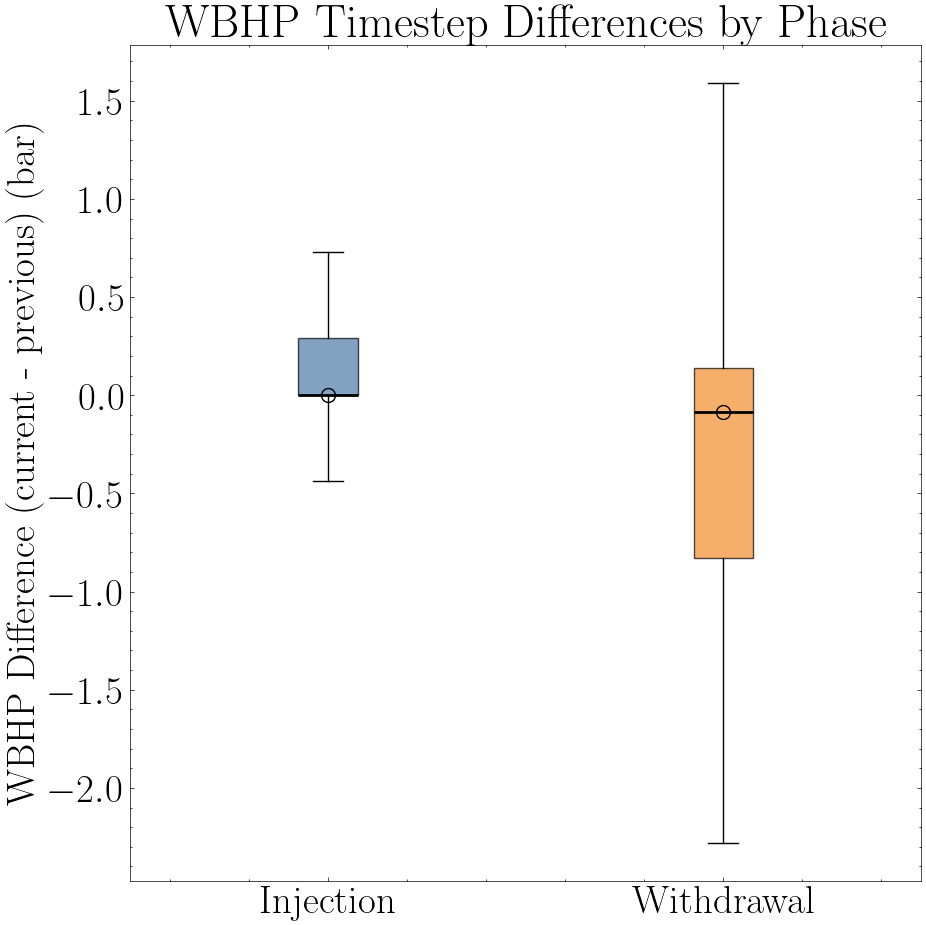

In [28]:
df_clean = df.dropna(subset=['wbhp_diff'])
df_clean = df_clean[df_clean['phase'].isin(['injection', 'withdrawal'])]
df_clean = df_clean[df_clean['wbhp_prev'] != 0]

fig, ax = plt.subplots(figsize=(10, 10))

groups = [df_clean[df_clean['phase'] == p]['wbhp_diff'].values
          for p in ['injection', 'withdrawal']]

box = ax.boxplot(
    groups,
    labels=['Injection', 'Withdrawal'],
    showfliers=False,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2)
)

colors = ['#4E79A7', '#F28E2B']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Overlay a hollow circle at each median
for i, median_line in enumerate(box['medians']):
    x, y = median_line.get_xdata(), median_line.get_ydata()
    x_center = np.mean(x)
    y_center = np.mean(y)
    ax.plot(x_center, y_center, marker='o', markerfacecolor='none',
             markeredgecolor='black', markersize=10, linestyle='none', zorder=5)

ax.set_ylabel('WBHP Difference (current - previous) (bar)')
ax.set_title('WBHP Timestep Differences by Phase')
plt.tight_layout()
plt.show()
fig.savefig('Figures/WBHP_box')

In [29]:
with open('../Results/autoregress_vals_added_inplace.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

df = pd.DataFrame.from_dict(Dense_dict)
df

ValueError: Per-column arrays must each be 1-dimensional

## Unnormalised inj and withdrawal in same row.

In [ ]:
with open('../Results/autoregress_errors.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

df = pd.DataFrame.from_dict(Dense_dict)

n_timesteps = 119
mae_teacher_forced = []
mae_autoregressive = []
mean_grid_drift = []

true_rate = df['true_rate']
pred_rate = df['pred_rate']
autoregressive_rate = df['autorate']
grid_drift = df['Grid_MSE']

for t in range(n_timesteps):
    true_t = np.array(true_rate[t])
    pred_t = np.array(pred_rate[t])
    ar_t = np.array(autoregressive_rate[t])

    unnormalised_true = []
    unnormalised_pred = []
    unnormalised_auto = []
    for idx, i in enumerate(true_t):
        if i < 0:
            unnormalised_true.append((inverse_min_max_norm(i*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr']))*-1)
            unnormalised_pred.append((inverse_min_max_norm(pred_t[idx]*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr']))*-1)
            unnormalised_auto.append((inverse_min_max_norm(ar_t[idx]*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr']))*-1)
        elif i > 0:
            unnormalised_true.append(inverse_min_max_norm(i, norm_stats['min_fcmir'], norm_stats['max_fcmir']))
            unnormalised_pred.append(inverse_min_max_norm(pred_t[idx], norm_stats['min_fcmir'], norm_stats['max_fcmir']))
            unnormalised_auto.append(inverse_min_max_norm(ar_t[idx], norm_stats['min_fcmir'], norm_stats['max_fcmir']))

        else:
            unnormalised_true.append(0)
            unnormalised_pred.append(0)
            unnormalised_auto.append(0)

    true_unnorm_arr = np.array(unnormalised_true)
    pred_real_unnorm_arr = np.array(unnormalised_pred)
    ar_real_unnorm_arr = np.array(unnormalised_auto)

    mae_teacher_forced.append(np.mean(np.abs(true_unnorm_arr - pred_real_unnorm_arr)))
    mae_autoregressive.append(np.mean(np.abs(true_unnorm_arr - ar_real_unnorm_arr)))
    mean_grid_drift.append(np.mean(grid_drift[t]))

## Inj and withdrawal split and not normalised

In [ ]:
def mean_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

In [ ]:
tw = Dense_df[Dense_df['True_test_inpl'] != 0]['True_test_inpl'].values
pw = Dense_df[Dense_df['True_test_inpl'] != 0]['Pred_test_inpl'].values

counter = 0
num_sets = 119

teacher_forced_pred_inplace = [[] for _ in range(num_sets)]

for idx, i in enumerate(tw):
    teacher_forced_pred_inplace[counter].append(pw[idx])
    counter += 1
    if counter == num_sets:
        counter = 0




In [ ]:
with open('../Results/autoregress_vals_added_inplace.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

# df_inplace = pd.DataFrame.from_dict(Dense_dict)
# df_inplace
Dense_dict

{'true_rate': array([[ 0.83505672,  0.76504761,  0.76249969, ..., -0.77509373,
          0.67322171,  0.41442376],
        [ 0.41442376,  0.71998739,  0.69552946, ..., -0.34438029,
         -0.27350095, -0.38051662],
        [-0.38051662, -0.4640052 ,  0.94693655, ...,  0.        ,
         -0.69022596, -0.45758903],
        ...,
        [ 0.61624396,  0.45518568,  0.35862306, ...,  0.        ,
          0.        , -0.71811658],
        [-0.71811658, -0.54445934,  0.35607171, ..., -0.44111222,
         -0.54164523,  0.        ],
        [ 0.        ,  0.        ,  0.56303728, ...,  0.03424368,
          0.02565568, -0.59639955]], shape=(157, 119)),
 'pred_rate': array([[ 0.83181274,  0.75827205,  0.74767458, ..., -0.44509131,
          0.70168173,  0.59509063],
        [ 0.59509063,  0.71507812,  0.68938494, ..., -0.35633811,
         -0.37717506, -0.39643922],
        [-0.39643922, -0.46126652,  0.93759108, ...,  0.        ,
         -0.47098845, -0.41680333],
        ...,
        [ 

In [ ]:
import pickle
from sklearn.metrics import mean_absolute_percentage_error

with open('../Results/autoregress_pressure_sat_added.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

df = pd.DataFrame.from_dict(Dense_dict)

n_timesteps = 119
mae_with_normal = []
mae_with_autoregressive = []


mae_injection_normal = []
mae_injection_autoregressive = []

mean_pred_grid_drift = []
mean_auto_grid_drift = []

mean_pred_sat_error = []
mean_auto_sat_error = []

mean_pred_pressure_error = []
mean_auto_pressure_error = []

teacher_forced_pred_inplace_mape = []
autoregressive_pred_inplace_mape = []

true_rate = df['true_rate']
pred_rate = df['pred_rate']
autoregressive_rate = df['autoregressive_rate']


pred_grid_drift = df['pred_grid_mse']
auto_grid_drift = df['auto_grid_mse']

pred_sat_error = df['pred_sat_error']
auto_sat_error = df['ar_sat_error']

pred_pressure_error = df['pred_pressure_error']
auto_pressure_error = df['ar_pressure_error']

for t in range(n_timesteps):
    true_t = np.array(true_rate[t])
    pred_t = np.array(pred_rate[t])
    ar_t = np.array(autoregressive_rate[t])

    unnormalised_with_true = []
    unnormalised_with_pred = []
    unnormalised_with_auto = []

    unnormalised_injection_true = []
    unnormalised_injection_pred = []
    unnormalised_injection_auto = []

    for idx, i in enumerate(true_t):
        if i < 0:
            unnormalised_with_true.append((inverse_min_max_norm(i*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])*-1))
            unnormalised_with_pred.append((inverse_min_max_norm(pred_t[idx]*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])*-1))
            unnormalised_with_auto.append((inverse_min_max_norm(ar_t[idx]*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])*-1))
        elif i > 0:
            unnormalised_injection_true.append(inverse_min_max_norm(i, norm_stats['min_fcmir'], norm_stats['max_fcmir']))
            unnormalised_injection_pred.append(inverse_min_max_norm(pred_t[idx], norm_stats['min_fcmir'], norm_stats['max_fcmir']))
            unnormalised_injection_auto.append(inverse_min_max_norm(ar_t[idx], norm_stats['min_fcmir'], norm_stats['max_fcmir']))


    true_unnorm_with_arr = np.array(unnormalised_with_true)
    pred_real_with_unnorm_arr = np.array(unnormalised_with_pred)
    ar_real_with_unnorm_arr = np.array(unnormalised_with_auto)

    true_unnorm_injection_arr = np.array(unnormalised_injection_true)
    pred_real_injection_unnorm_arr = np.array(unnormalised_injection_pred)
    ar_real_injection_unnorm_arr = np.array(unnormalised_injection_auto)

    unnormalised_injection_true_arr = np.array(unnormalised_injection_true)
    unnormalised_injection_pred_arr = np.array(unnormalised_injection_pred)
    unnormalised_injection_auto_arr = np.array(unnormalised_injection_auto)

    mae_with_normal.append(mean_absolute_percentage_error(true_unnorm_with_arr, pred_real_with_unnorm_arr))
    mae_with_autoregressive.append(mean_absolute_percentage_error(true_unnorm_with_arr, ar_real_with_unnorm_arr))

    mae_injection_normal.append(mean_absolute_percentage_error(true_unnorm_injection_arr, pred_real_injection_unnorm_arr))
    mae_injection_autoregressive.append(mean_absolute_percentage_error(true_unnorm_injection_arr, ar_real_injection_unnorm_arr))

    mean_pred_grid_drift.append(np.mean(pred_grid_drift[t]))
    mean_auto_grid_drift.append(np.mean(auto_grid_drift[t]))

    mean_pred_sat_error.append(np.mean(pred_sat_error[t]))
    mean_auto_sat_error.append(np.mean(auto_sat_error[t]))

    mean_pred_pressure_error.append(np.mean(pred_pressure_error[t]))
    mean_auto_pressure_error.append(np.mean(auto_pressure_error[t]))

## Normalised not split

In [ ]:
with open('../Results/autoregress_pressure_sat_added.pkl', 'rb') as f:
    Dense_dict = pickle.load(f)

df = pd.DataFrame.from_dict(Dense_dict)

n_timesteps = 119
mae_teacher_forced = []
mae_autoregressive = []
mean_pred_grid_drift = []
mean_auto_grid_drift = []


true_rate = df['true_rate']
pred_rate = df['pred_rate']
autoregressive_rate = df['autoregressive_rate']
pred_grid_drift = df['pred_grid_mse']
auto_grid_drift = df['auto_grid_mse']

for t in range(n_timesteps):
    true_t = np.array(true_rate[t])
    pred_t = np.array(pred_rate[t])
    ar_t = np.array(autoregressive_rate[t])

    # unnormalised_true = []
    # unnormalised_pred = []
    # unnormalised_auto = []
    # for idx, i in enumerate(true_t):
    #     if i < 0:
    #         unnormalised_true.append((inverse_min_max_norm(i*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr']))*-1)
    #         unnormalised_pred.append((inverse_min_max_norm(pred_t[idx]*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr']))*-1)
    #         unnormalised_auto.append((inverse_min_max_norm(ar_t[idx]*-1, norm_stats['min_fcmpr'], norm_stats['max_fcmpr']))*-1)
    #     elif i > 0:
    #         unnormalised_true.append(inverse_min_max_norm(i, norm_stats['min_fcmir'], norm_stats['max_fcmir']))
    #         unnormalised_pred.append(inverse_min_max_norm(pred_t[idx], norm_stats['min_fcmir'], norm_stats['max_fcmir']))
    #         unnormalised_auto.append(inverse_min_max_norm(ar_t[idx], norm_stats['min_fcmir'], norm_stats['max_fcmir']))

    #     else:
    #         unnormalised_true.append(0)
    #         unnormalised_pred.append(0)
    #         unnormalised_auto.append(0)

    true_unnorm_arr = np.array(true_t)
    pred_real_unnorm_arr = np.array(pred_t)
    ar_real_unnorm_arr = np.array(ar_t)

    mae_teacher_forced.append(np.mean((true_unnorm_arr - pred_real_unnorm_arr)))
    mae_autoregressive.append(np.mean((true_unnorm_arr - ar_real_unnorm_arr)))
    mean_pred_grid_drift.append(np.mean(pred_grid_drift[t]))
    mean_auto_grid_drift.append(np.mean(auto_grid_drift[t]))

Index(['true_rate', 'pred_rate', 'autoregressive_rate', 'true_inj', 'pred_inj',
       'ar_inj', 'true_with', 'pred_with', 'ar_with', 'true_inplace',
       'pred_inplace', 'ar_inplace_trace'],
      dtype='object')


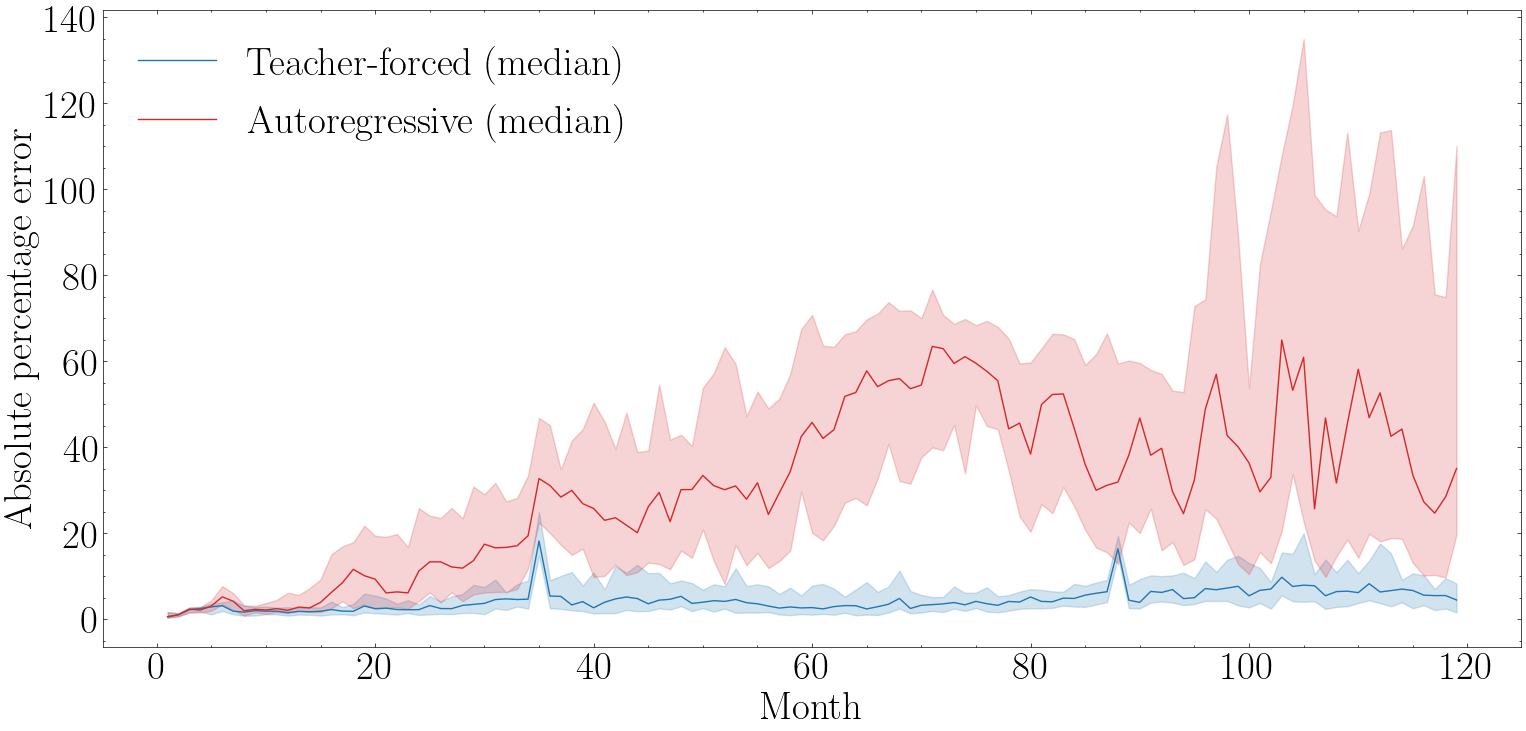

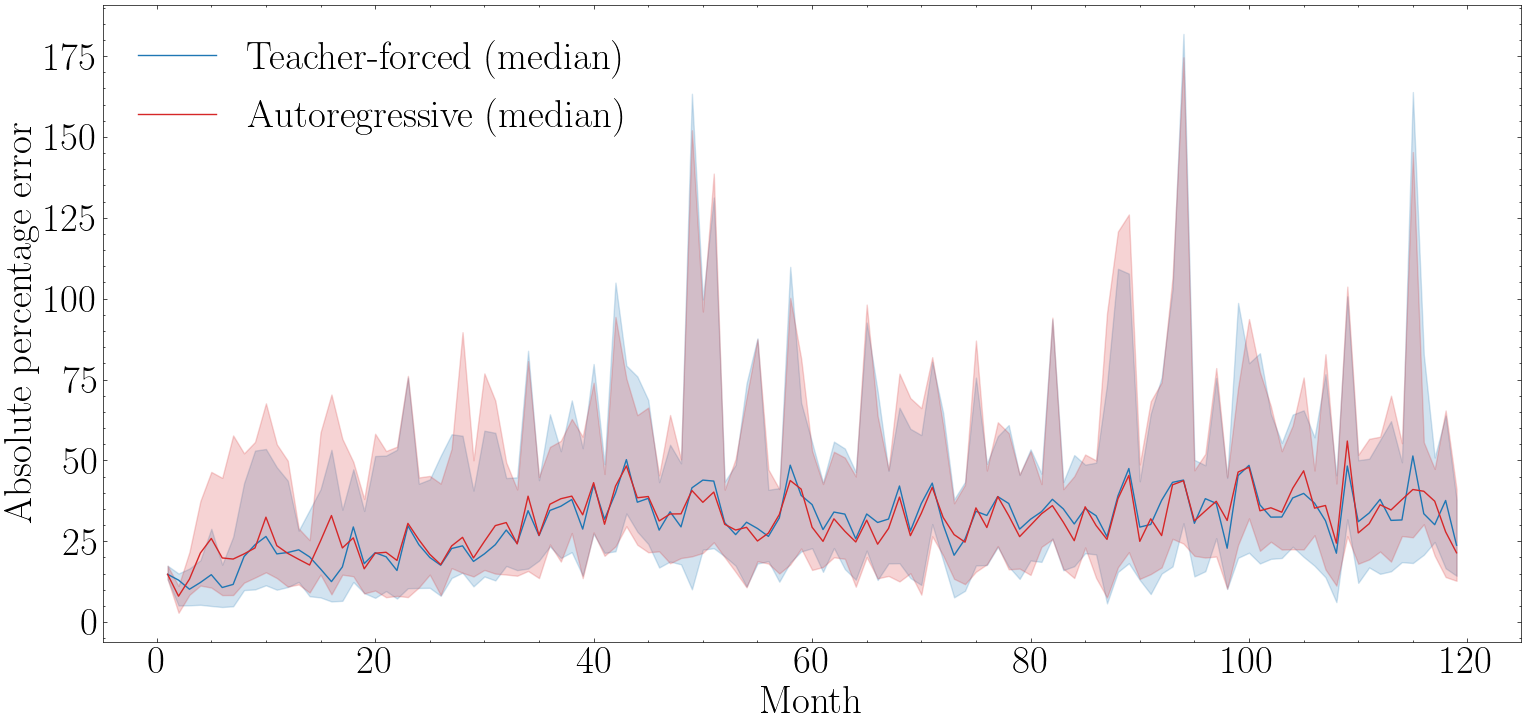

In [ ]:
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

with open('../Results/autoregress_vals_split_inj_with_no_grid.pkl', 'rb') as f:
    df = pickle.load(f)

df = pd.DataFrame.from_dict(df)
print(df.columns)

n_timesteps = 119
threshold = 1e-3  # pick something physically meaningful relative to your typical rate scale

with_normal_errors = []
with_autoregressive_errors = []

injection_normal_errors = []
injection_autoregressive_errors = []

true_inj = df['true_inj']
pred_inj = df['pred_inj']
ar_inj = df['ar_inj']

true_with = df['true_with']
pred_with = df['pred_with']
ar_with = df['ar_with']

for t in range(n_timesteps):
    true_with_t = np.array(true_with[t])
    pred_with_t = np.array(pred_with[t])
    ar_with_t = np.array(ar_with[t])

    unnorm_with_true = inverse_min_max_norm(true_with_t, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])
    unnorm_with_pred = inverse_min_max_norm(pred_with_t, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])
    unnorm_with_auto = inverse_min_max_norm(ar_with_t, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])

    active_mask = np.abs(unnorm_with_true) > threshold
    unnorm_with_true = unnorm_with_true[active_mask]
    unnorm_with_pred = unnorm_with_pred[active_mask]
    unnorm_with_auto = unnorm_with_auto[active_mask]

    if len(unnorm_with_true) > 1:
        with_normal_errors.append(np.abs((unnorm_with_true - unnorm_with_pred) / unnorm_with_true)*100)
        with_autoregressive_errors.append(np.abs((unnorm_with_true - unnorm_with_auto) / unnorm_with_true)*100)
    else:
        with_normal_errors.append(np.array([np.nan]))
        with_autoregressive_errors.append(np.array([np.nan]))

    true_inj_t = np.array(true_inj[t])
    pred_inj_t = np.array(pred_inj[t])
    ar_inj_t = np.array(ar_inj[t])

    unnorm_inj_true = inverse_min_max_norm(true_inj_t, norm_stats['min_fcmir'], norm_stats['max_fcmir'])
    unnorm_inj_pred = inverse_min_max_norm(pred_inj_t, norm_stats['min_fcmir'], norm_stats['max_fcmir'])
    unnorm_inj_auto = inverse_min_max_norm(ar_inj_t, norm_stats['min_fcmir'], norm_stats['max_fcmir'])

    active_mask = np.abs(unnorm_inj_true) > threshold
    unnorm_inj_true = unnorm_inj_true[active_mask]
    unnorm_inj_pred = unnorm_inj_pred[active_mask]
    unnorm_inj_auto = unnorm_inj_auto[active_mask]

    if len(unnorm_inj_true) > 1:
        injection_normal_errors.append(np.abs((unnorm_inj_true - unnorm_inj_pred) / unnorm_inj_true)*100)
        injection_autoregressive_errors.append(np.abs((unnorm_inj_true - unnorm_inj_auto) / unnorm_inj_true)*100)
    else:
        injection_normal_errors.append(np.array([np.nan]))
        injection_autoregressive_errors.append(np.array([np.nan]))


def summarise(err_list):
    median = np.array([np.nanmedian(e) for e in err_list])
    q25 = np.array([np.nanpercentile(e, 25) for e in err_list])
    q75 = np.array([np.nanpercentile(e, 75) for e in err_list])
    return median, q25, q75

with_med, with_q25, with_q75 = summarise(with_normal_errors)
with_ar_med, with_ar_q25, with_ar_q75 = summarise(with_autoregressive_errors)

inj_med, inj_q25, inj_q75 = summarise(injection_normal_errors)
inj_ar_med, inj_ar_q25, inj_ar_q75 = summarise(injection_autoregressive_errors)

timesteps = np.arange(n_timesteps) + 1

# --- injection plot ---
fig, ax  = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, inj_med, label='Teacher-forced (median)', color='tab:blue')
ax.fill_between(timesteps, inj_q25, inj_q75, color='tab:blue', alpha=0.2)

ax.plot(timesteps, inj_ar_med, label='Autoregressive (median)', color='tab:red')
ax.fill_between(timesteps, inj_ar_q25, inj_ar_q75, color='tab:red', alpha=0.2)

ax.set_xlabel('Month')
ax.set_ylabel('Absolute percentage error')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('Figures/Inj_autoreg_plot.png', dpi=300)
plt.show()


# --- withdrawal plot ---
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, with_med, label='Teacher-forced (median)', color='tab:blue')
ax.fill_between(timesteps, with_q25, with_q75, color='tab:blue', alpha=0.2)

ax.plot(timesteps, with_ar_med, label='Autoregressive (median)', color='tab:red')
ax.fill_between(timesteps, with_ar_q25, with_ar_q75, color='tab:red', alpha=0.2)

ax.set_xlabel('Month')
ax.set_ylabel('Absolute percentage error')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('Figures/With_autoreg_plot.png', dpi=300)
plt.show()

Index(['true_rate', 'pred_rate', 'autoregressive_rate', 'true_inj', 'pred_inj',
       'ar_inj', 'true_with', 'pred_with', 'ar_with', 'true_inplace',
       'pred_inplace', 'ar_inplace_trace'],
      dtype='object')
INPLACE


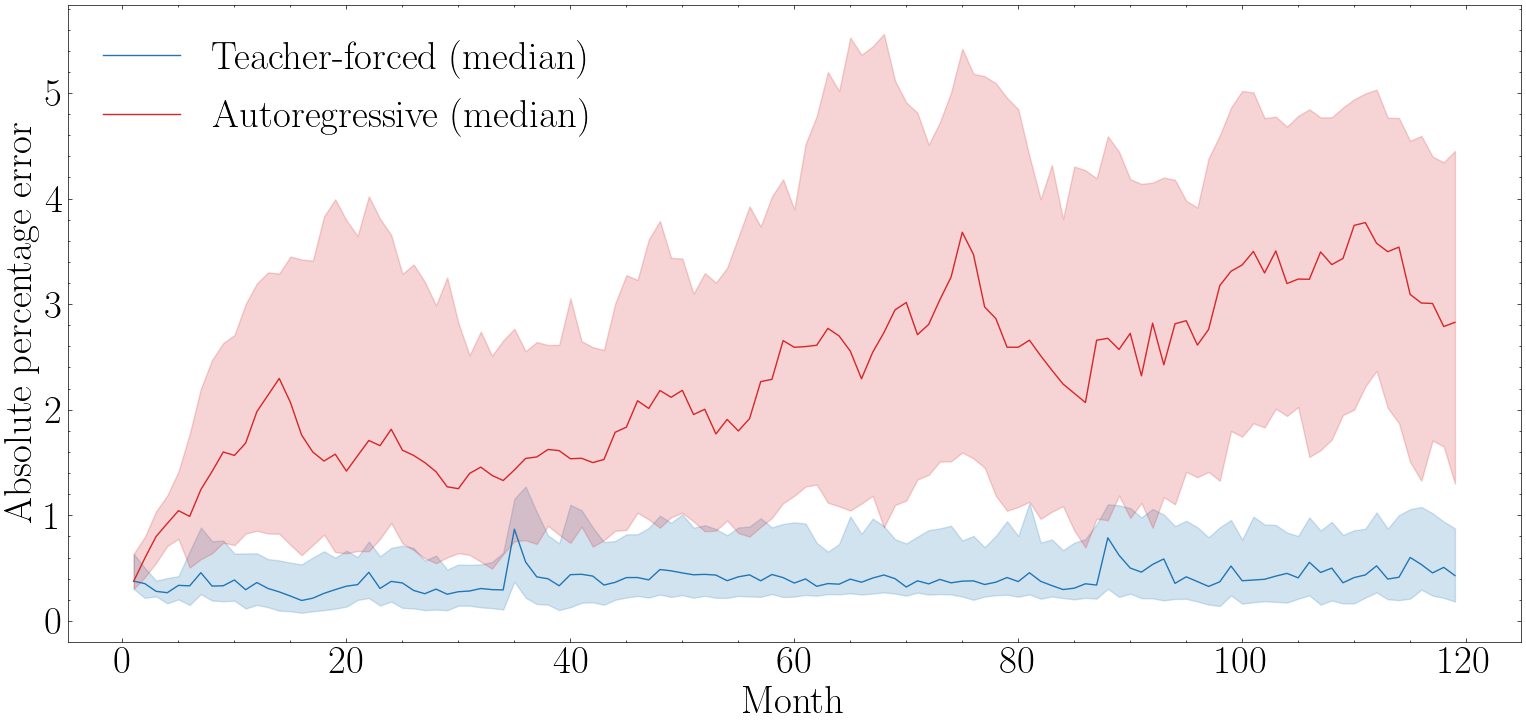

In [ ]:
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

with open('../Results/autoregress_vals_split_inj_with_no_grid.pkl', 'rb') as f:
    df = pickle.load(f)

df = pd.DataFrame.from_dict(df)
print(df.columns)

n_timesteps = 119
threshold = 1e-3  # pick something physically meaningful relative to your typical rate scale

with_normal_errors = []
with_autoregressive_errors = []

inplace_normal_errors = []
inplace_autoregressive_errors = []

true_inplace = df['true_inplace']
pred_inplace = df['pred_inplace']
ar_inplace = df['ar_inplace_trace']

true_with = df['true_with']
pred_with = df['pred_with']
ar_with = df['ar_with']

for t in range(n_timesteps):
    true_with_t = np.array(true_with[t])
    pred_with_t = np.array(pred_with[t])
    ar_with_t = np.array(ar_with[t])

    unnorm_with_true = inverse_min_max_norm(true_with_t, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])
    unnorm_with_pred = inverse_min_max_norm(pred_with_t, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])
    unnorm_with_auto = inverse_min_max_norm(ar_with_t, norm_stats['min_fcmpr'], norm_stats['max_fcmpr'])

    active_mask = np.abs(unnorm_with_true) > threshold
    unnorm_with_true = unnorm_with_true[active_mask]
    unnorm_with_pred = unnorm_with_pred[active_mask]
    unnorm_with_auto = unnorm_with_auto[active_mask]

    if len(unnorm_with_true) > 1:
        with_normal_errors.append(np.abs((unnorm_with_true - unnorm_with_pred) / unnorm_with_true)*100)
        with_autoregressive_errors.append(np.abs((unnorm_with_true - unnorm_with_auto) / unnorm_with_true)*100)
    else:
        with_normal_errors.append(np.array([np.nan]))
        with_autoregressive_errors.append(np.array([np.nan]))

    true_inplace_t = np.array(true_inplace[t])
    pred_inplace_t = np.array(pred_inplace[t])
    ar_inplace_t = np.array(ar_inplace[t])

    unnorm_inplace_true = inverse_min_max_norm(true_inplace_t, norm_stats['min_fcmip'], norm_stats['max_fcmip'])
    unnorm_inplace_pred = inverse_min_max_norm(pred_inplace_t, norm_stats['min_fcmip'], norm_stats['max_fcmip'])
    unnorm_inplace_auto = inverse_min_max_norm(ar_inplace_t, norm_stats['min_fcmip'], norm_stats['max_fcmip'])

    active_mask = np.abs(unnorm_inplace_true) > threshold
    unnorm_inplace_true = unnorm_inplace_true[active_mask]
    unnorm_inplace_pred = unnorm_inplace_pred[active_mask]
    unnorm_inplace_auto = unnorm_inplace_auto[active_mask]

    if len(unnorm_inplace_true) > 1:
        inplace_normal_errors.append(np.abs((unnorm_inplace_true - unnorm_inplace_pred) / unnorm_inplace_true)*100)
        inplace_autoregressive_errors.append(np.abs((unnorm_inplace_true - unnorm_inplace_auto) / unnorm_inplace_true)*100)
    else:
        inplace_normal_errors.append(np.array([np.nan]))
        inplace_autoregressive_errors.append(np.array([np.nan]))


def summarise(err_list):
    median = np.array([np.nanmedian(e) for e in err_list])
    q25 = np.array([np.nanpercentile(e, 25) for e in err_list])
    q75 = np.array([np.nanpercentile(e, 75) for e in err_list])
    return median, q25, q75

inj_med, inj_q25, inj_q75 = summarise(inplace_normal_errors)
inj_ar_med, inj_ar_q25, inj_ar_q75 = summarise(inplace_autoregressive_errors)

timesteps = np.arange(n_timesteps) + 1


print("INPLACE")
fig, ax  = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, inj_med, label='Teacher-forced (median)', color='tab:blue')
ax.fill_between(timesteps, inj_q25, inj_q75, color='tab:blue', alpha=0.2)

ax.plot(timesteps, inj_ar_med, label='Autoregressive (median)', color='tab:red')
ax.fill_between(timesteps, inj_ar_q25, inj_ar_q75, color='tab:red', alpha=0.2)

ax.set_xlabel('Month')
ax.set_ylabel('Absolute percentage error')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('Figures/Inplace_autoreg_plot_ape.png', dpi=300)
plt.show()


Index(['true_rate', 'pred_rate', 'autoregressive_rate', 'true_inj', 'pred_inj',
       'ar_inj', 'true_with', 'pred_with', 'ar_with', 'true_inplace',
       'pred_inplace', 'ar_inplace_trace'],
      dtype='object')


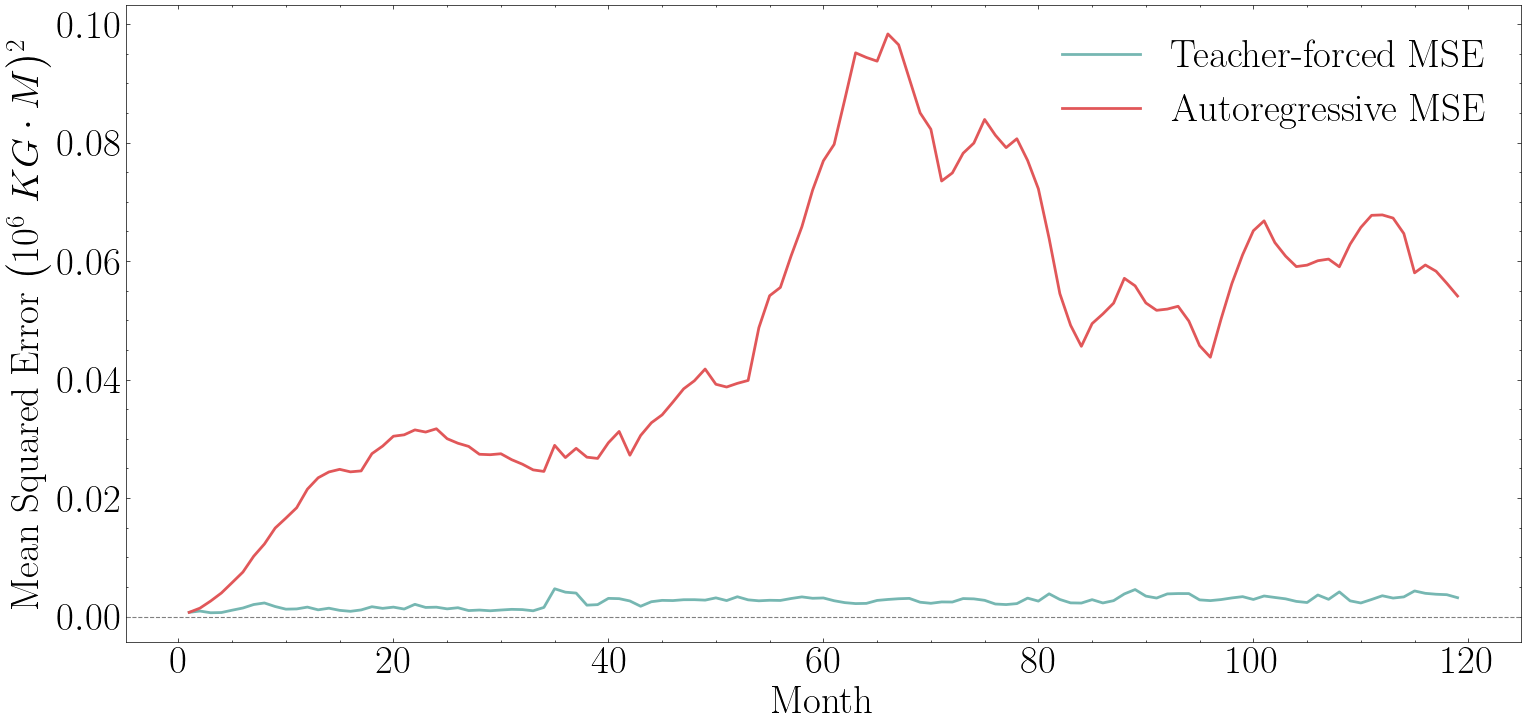

In [ ]:
import pickle
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error, mean_squared_error

with open('../Results/autoregress_vals_split_inj_with_no_grid.pkl', 'rb') as f:
    df = pickle.load(f)

df = pd.DataFrame.from_dict(df)
print(df.columns)

n_timesteps = 119
threshold = 1e-3  # mask out near-zero true inplace values to avoid division blow-up

true_inplace = df['true_inplace']
pred_inplace = df['pred_inplace']
ar_inplace = df['ar_inplace_trace']

mpe_inplace_normal = []
mpe_inplace_autoregressive = []

for t in range(n_timesteps):
    true_inplace_t = np.array(true_inplace[t])
    pred_inplace_t = np.array(pred_inplace[t])
    ar_inplace_t = np.array(ar_inplace[t])

    unnorm_inplace_true = inverse_min_max_norm(true_inplace_t, norm_stats['min_fcmip'], norm_stats['max_fcmip'])
    unnorm_inplace_pred = inverse_min_max_norm(pred_inplace_t, norm_stats['min_fcmip'], norm_stats['max_fcmip'])
    unnorm_inplace_auto = inverse_min_max_norm(ar_inplace_t, norm_stats['min_fcmip'], norm_stats['max_fcmip'])

    active_mask = np.abs(unnorm_inplace_true) > threshold
    unnorm_inplace_true = unnorm_inplace_true[active_mask]
    unnorm_inplace_pred = unnorm_inplace_pred[active_mask]
    unnorm_inplace_auto = unnorm_inplace_auto[active_mask]

    if len(unnorm_inplace_true) > 0:
        # signed mean percentage error (not absolute) - shows over/under prediction bias
        mpe_inplace_normal.append(mean_squared_error(unnorm_inplace_pred, unnorm_inplace_true))
        mpe_inplace_autoregressive.append(mean_squared_error(unnorm_inplace_auto, unnorm_inplace_true))
    else:
        mpe_inplace_normal.append(np.nan)
        mpe_inplace_autoregressive.append(np.nan)

mpe_inplace_normal = np.array(mpe_inplace_normal) / 10e12
mpe_inplace_autoregressive = np.array(mpe_inplace_autoregressive) / 10e12

timesteps = np.arange(n_timesteps) + 1

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, mpe_inplace_normal, label='Teacher-forced MSE', color='#76B7B2', linewidth=2)
ax.plot(timesteps, mpe_inplace_autoregressive, label='Autoregressive MSE', color='#E15759', linewidth=2)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('Month')
ax.set_ylabel(r'Mean Squared Error $\left ( 10^{6} \ {KG \cdot M} \right)$$^2$')
ax.legend()
fig.tight_layout()
fig.savefig('Figures/Inplace_MSE_plot.png', dpi=300)
plt.show()

Index(['Pressure_mse_teacher', 'Pressure_mse_autoregressive',
       'Pressure_mpe_teacher', 'Pressure_mpe_auto', 'Saturation_mse_auto',
       'Saturation mse_teach'],
      dtype='object')


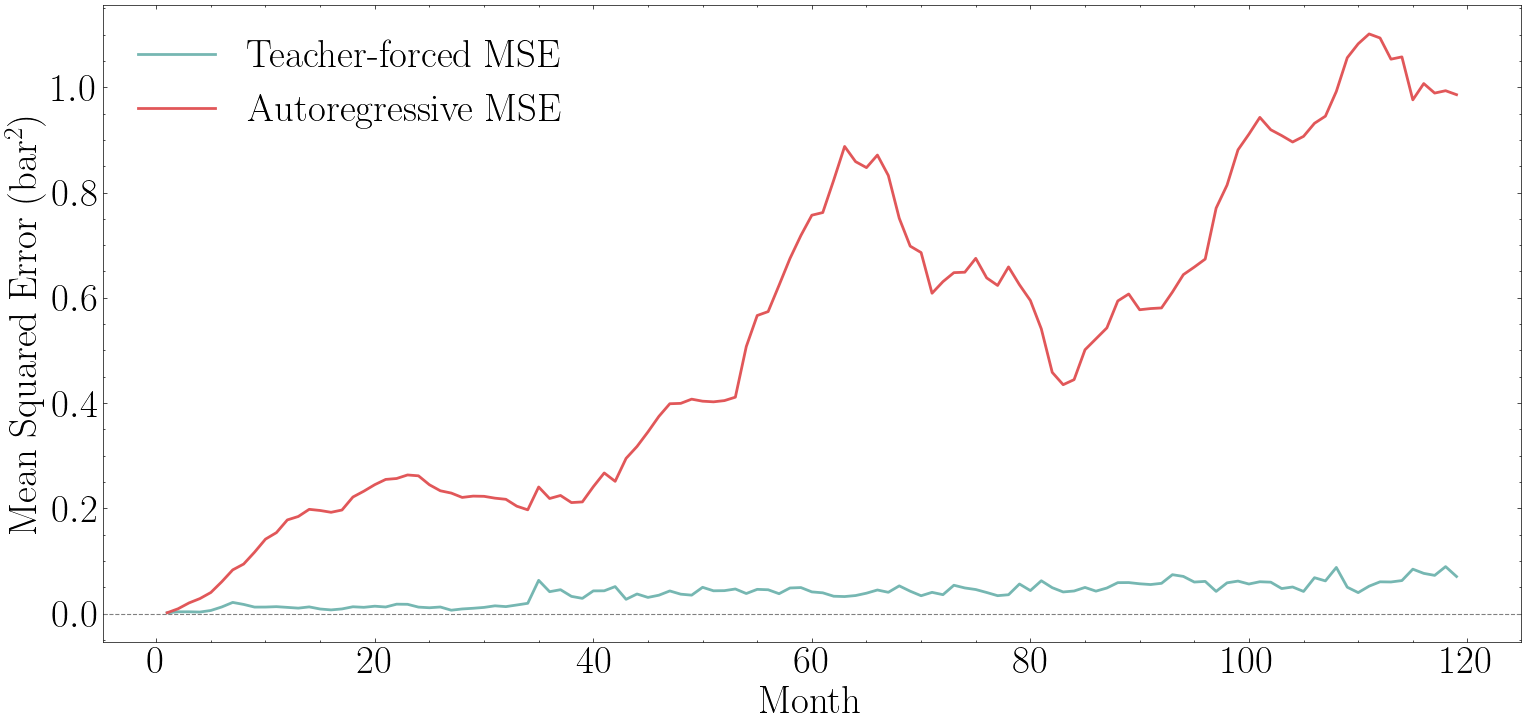

In [ ]:
import pickle

with open('../Results/autoregress_pressure_percent_error.pkl', 'rb') as f:
    dict_data = pickle.load(f)

df = pd.DataFrame.from_dict(dict_data)
print(df.columns)

timesteps = np.arange(n_timesteps) + 1

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, df['Pressure_mse_teacher'], label='Teacher-forced MSE', color='#76B7B2', linewidth=2)
ax.plot(timesteps, df['Pressure_mse_autoregressive'], label='Autoregressive MSE', color='#E15759', linewidth=2)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('Month')
ax.set_ylabel('Mean Squared Error (bar$^2$)')
ax.legend()
fig.tight_layout()
fig.savefig('Figures/Pressure_MSE_plot.png', dpi=300)
plt.show()

Index(['Pressure_mse_teacher', 'Pressure_mse_autoregressive',
       'Pressure_mpe_teacher', 'Pressure_mpe_auto', 'Saturation_mse_auto',
       'Saturation mse_teach'],
      dtype='object')


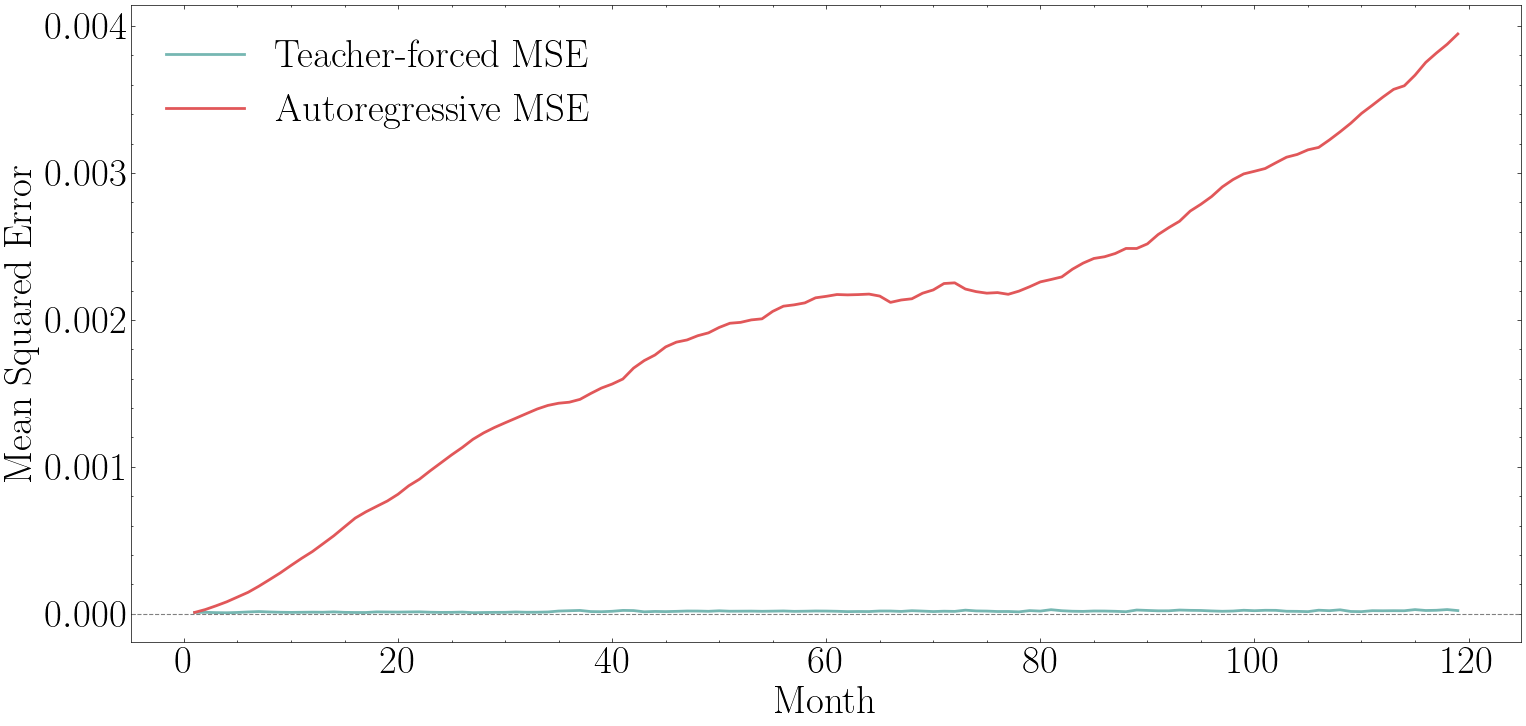

In [ ]:
import pickle

with open('../Results/autoregress_pressure_percent_error.pkl', 'rb') as f:
    dict_data = pickle.load(f)

df = pd.DataFrame.from_dict(dict_data)
print(df.columns)

timesteps = np.arange(n_timesteps) +1

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, df['Saturation mse_teach'], label='Teacher-forced MSE', color='#76B7B2', linewidth=2)
ax.plot(timesteps, df['Saturation_mse_auto'], label='Autoregressive MSE', color='#E15759', linewidth=2)
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('Month')
ax.set_ylabel('Mean Squared Error')
ax.legend()
fig.tight_layout()
fig.savefig('Figures/Saturation_MSE_plot.png', dpi=300)
plt.show()

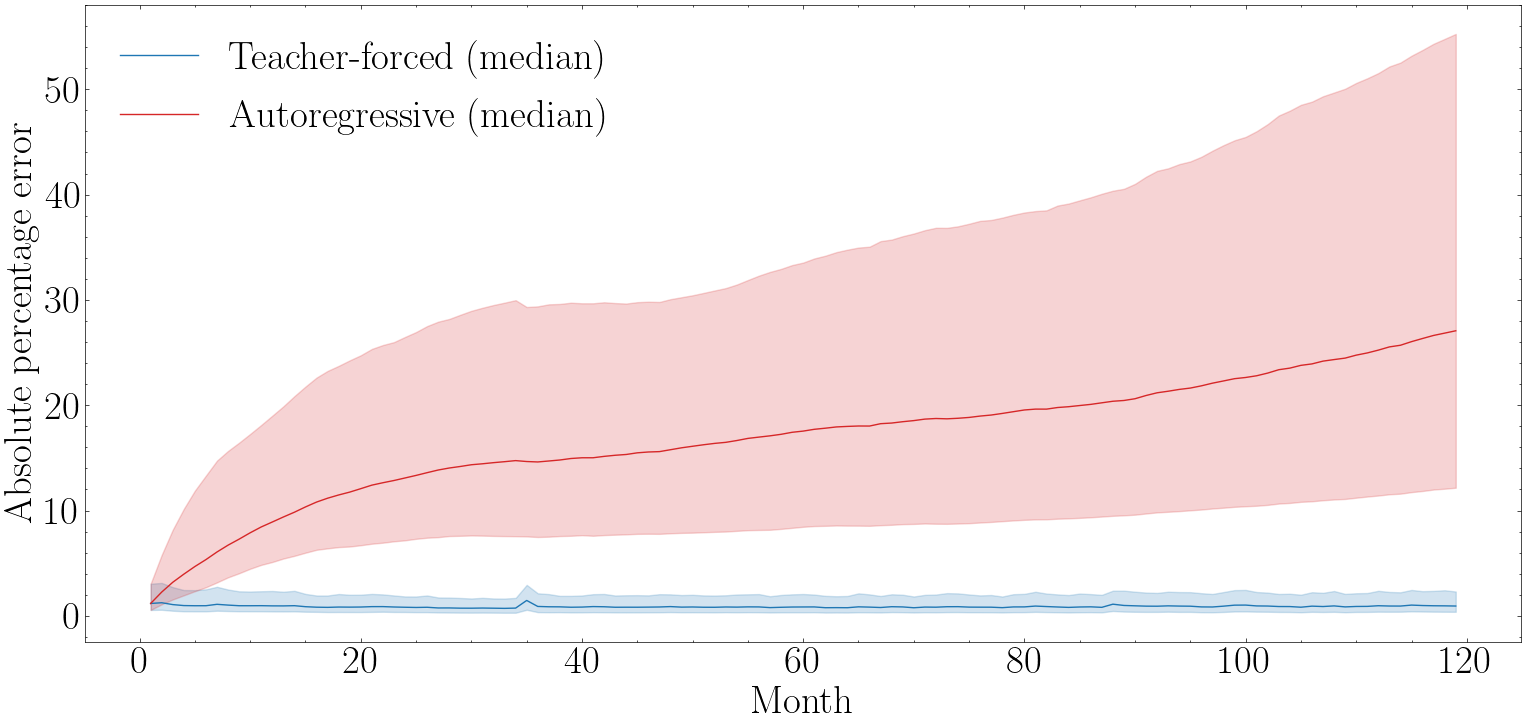

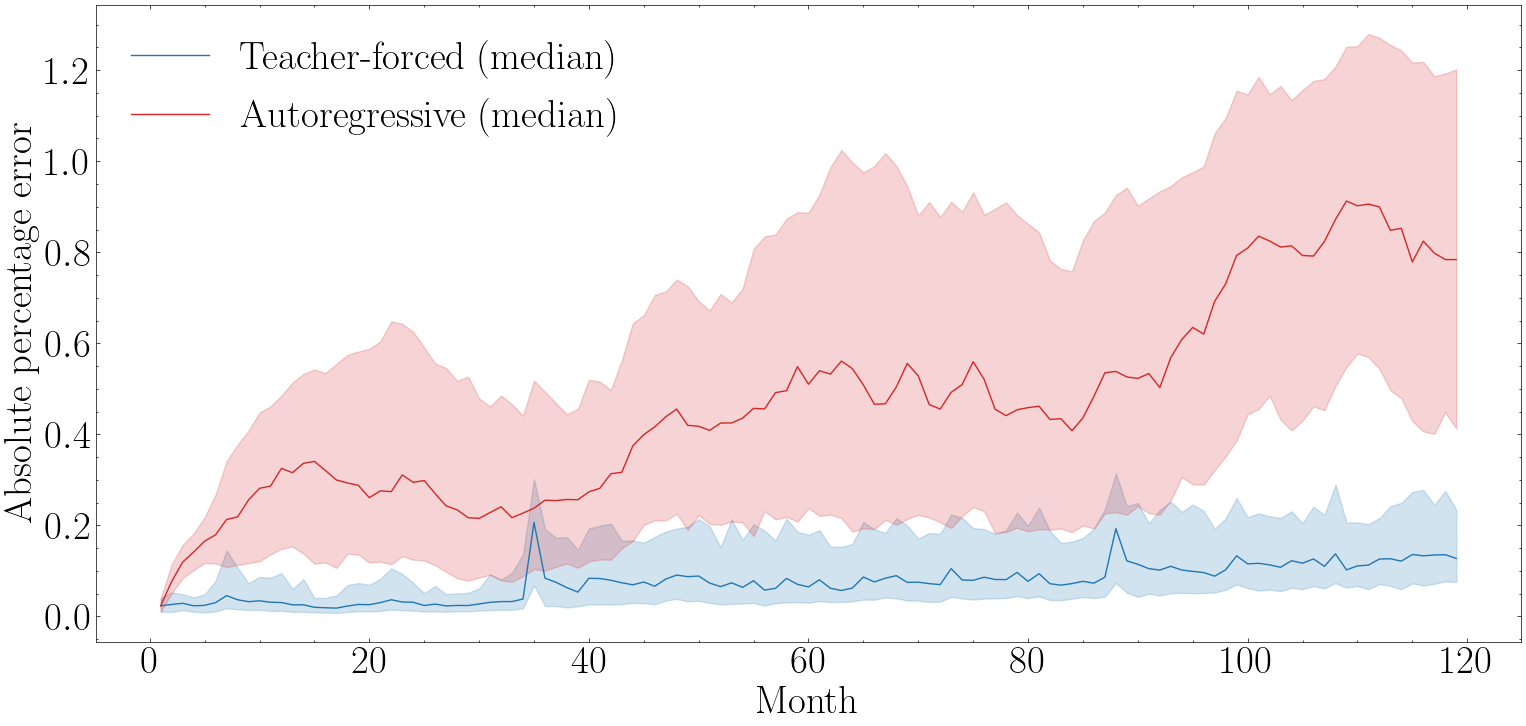

In [4]:
import pickle

with open('../Results/sat_press_abs_percent_error.pkl', 'rb') as f:
    dict_data = pickle.load(f)



sat_med = dict_data['sat_normal']['median']
sat_q25 = dict_data['sat_normal']['q25']
sat_q75 = dict_data['sat_normal']['q75']


sat_ar_med = dict_data['sat_autoregressive']['median']
sat_ar_q25 = dict_data['sat_autoregressive']['q25']
sat_ar_q75 = dict_data['sat_autoregressive']['q75']

pres_med = dict_data['pressure_normal']['median']
pres_q25 = dict_data['pressure_normal']['q25']
pres_q75 = dict_data['pressure_normal']['q75']
pres_ar_med = dict_data['pressure_autoregressive']['median']
pres_ar_q25 = dict_data['pressure_autoregressive']['q25']
pres_ar_q75 = dict_data['pressure_autoregressive']['q75']

n_timesteps = 119
timesteps = np.arange(n_timesteps) +1

fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, sat_med, label='Teacher-forced (median)', color='tab:blue')
ax.fill_between(timesteps, sat_q25, sat_q75, color='tab:blue', alpha=0.2)

ax.plot(timesteps, sat_ar_med, label='Autoregressive (median)', color='tab:red')
ax.fill_between(timesteps, sat_ar_q25, sat_ar_q75, color='tab:red', alpha=0.2)

ax.set_xlabel('Month')
ax.set_ylabel('Absolute percentage error')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('Figures/Saturation_autoreg_plot_ape.png', dpi=300)
plt.show()



# --- pressure plot ---
fig, ax = plt.subplots(figsize=(16, 8))
ax.plot(timesteps, pres_med, label='Teacher-forced (median)', color='tab:blue')
ax.fill_between(timesteps, pres_q25, pres_q75, color='tab:blue', alpha=0.2)

ax.plot(timesteps, pres_ar_med, label='Autoregressive (median)', color='tab:red')
ax.fill_between(timesteps, pres_ar_q25, pres_ar_q75, color='tab:red', alpha=0.2)

ax.set_xlabel('Month')
ax.set_ylabel('Absolute percentage error')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig('Figures/Pressure_autoreg_plot_ape.png', dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 8), dpi=800)

ax.text(
    0.5, 0.5,
    r'Horizontal           Permeability (mD)',
    transform=ax.transAxes,
    ha='center',
    va='center',
    bbox=dict(facecolor='white', edgecolor='none')
)
fig.savefig('Figures/3D_axes.png', dpi=800)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>